In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df=pd.read_csv('credit_risk_dataset.csv')
df.head()


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [9]:
df.shape
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [10]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [11]:
df.head(

)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [12]:
df['loan_status'].unique()

df['loan_status'].value_counts()


loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

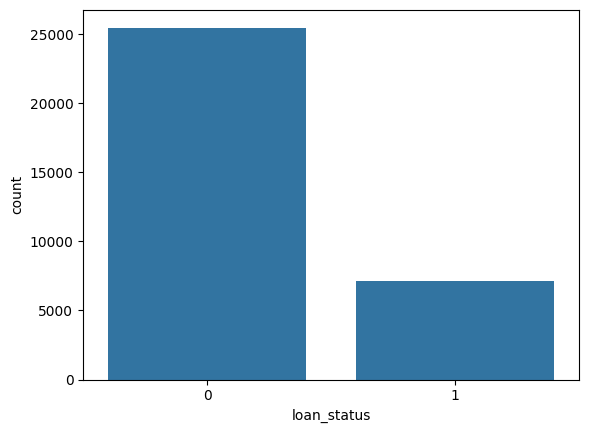

In [13]:
sns.countplot(x='loan_status',data=df
)

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')


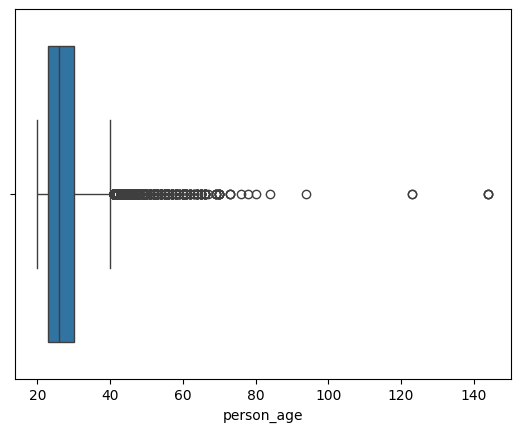

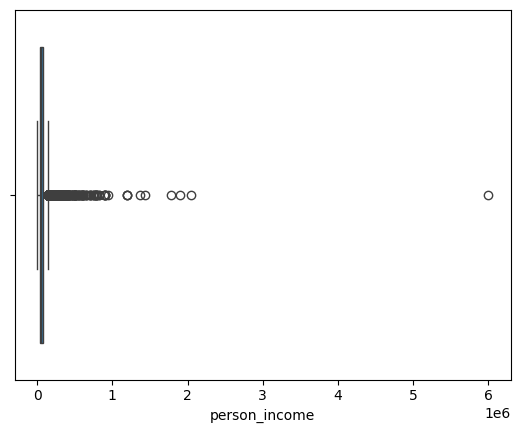

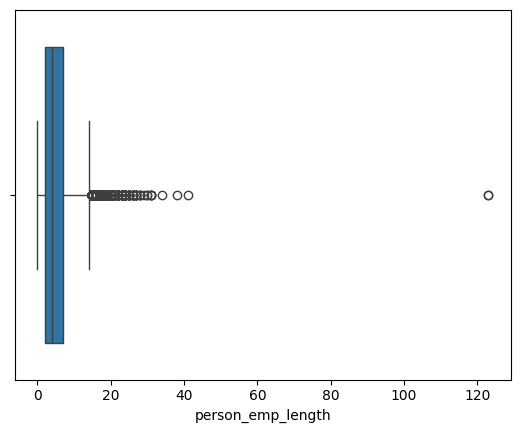

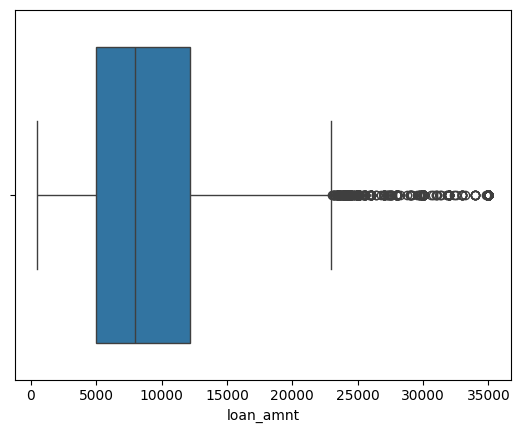

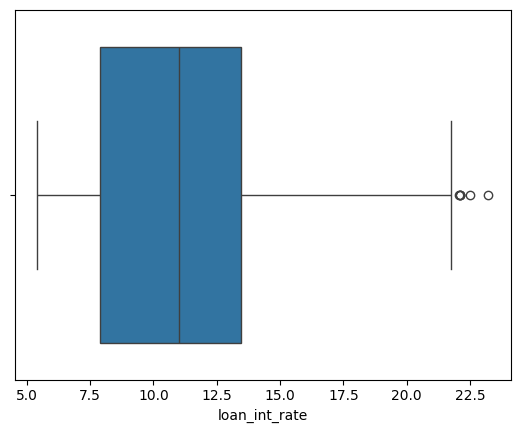

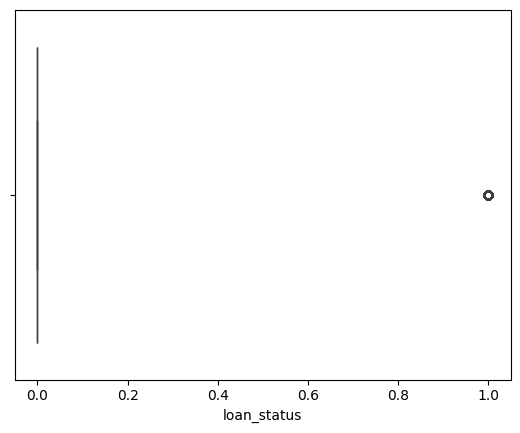

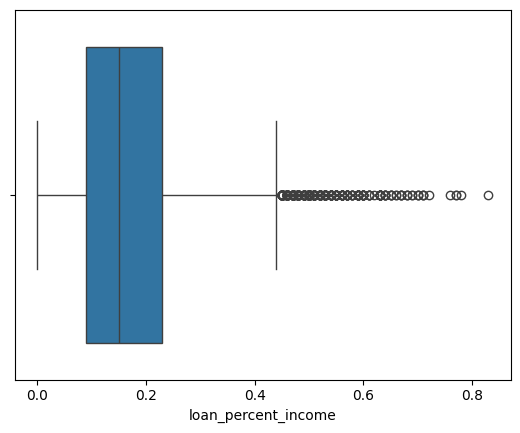

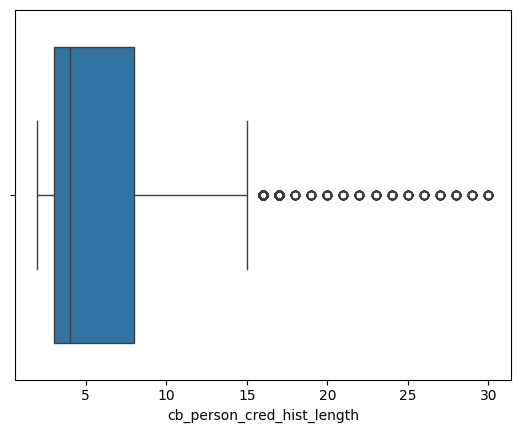

In [14]:
numerical_cols = df.select_dtypes(include=np.number).columns
print(numerical_cols)

for i in  numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [15]:
df.describe()


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [16]:
(df['person_age'] > 100).sum()

np.int64(5)

In [17]:
(df['person_emp_length'] > 60 ).sum()

np.int64(2)

<Axes: >

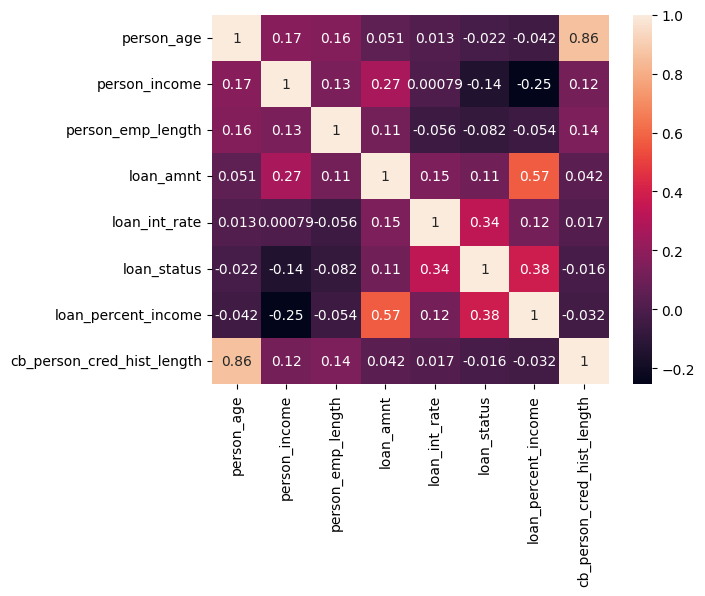

In [18]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [19]:
df_copy = df.copy()
print(f"Original Rows: {df_copy.shape[0]} ")
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates {df_copy.shape[0]}")

#Remove ages below 18 or above 100
df_copy=df_copy[df_copy['person_age'] >=18]
df_copy=df_copy[df_copy['person_age'] <=100]
#Remove employment length

df_copy=df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy=df_copy[df_copy['person_emp_length'] <= 60]

df_copy = df_copy[df_copy['loan_amnt'] > 0 ]

#Check if interest rate looks realistic

print(f"Loan interest rate range from (min:5.42 and max:23.22)")

Original Rows: 32581 
Rows after removing duplicates 32416
Loan interest rate range from (min:5.42 and max:23.22)


In [20]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [21]:
X= df_copy.drop('loan_status', axis=1)
y= df_copy['loan_status']

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [23]:
df.select_dtypes(include=np.object_).columns

Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')

In [24]:
numerical_cols=['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']
categorical_cols=['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']


In [25]:
neg, pos = np.bincount(y_train)
scale_weights = neg / pos

In [26]:

scale_weights

np.float64(3.6312213039485766)

In [27]:
#Logistic Regression : impute + SCALE numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers = [
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())

        ]),numerical_cols),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [28]:
from sklearn.metrics import accuracy_score,classification_report, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve
def evaluate_model(model_name,model, X_test, y_test,threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold :
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #metrices

  accuracy = accuracy_score(y_test, y_pred)
  precision_s = precision_score(y_test, y_pred)
  recall_s = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)


  #Confusion Matrix
  conf_matrix = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  print(f"{model_name} Metrices:")
  print(f"Best Threshold : {threshold}")
  print(f"Accuracy:{accuracy:.2f}")
  print(f"Precision:{precision_s:.2f}")
  print(f"Recall:{recall_s:.2f}")
  print(f"F1:{f1:.2f}")
  print()
  print(f"{model_name}:classification_report:")
  print(class_report)

  #Plotting Confusion Matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()

  #Plotting ROC-AUC
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()




In [29]:
#XGBOOST: impute numeric only, impute + One-Hot-Encoding
preprocessor_xg = ColumnTransformer(
    transformers = [
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]),numerical_cols),

        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [30]:
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy','precision':'precision','f1':'f1','recall':'recall'}


In [31]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline=Pipeline([
    ('preprocessor',preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [32]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('clssifier',XGBClassifier(
        n_estimator=300, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_weights, random_state=42
    ))
])

xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constan...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [33]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:
                      cv_results= cross_validate(pipe, X_train, y_train,cv=cv,scoring=scoring,n_jobs=-1)
                      print(cv_name)
                      print(f"ROC-AUC: {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
                      print(f"Precision: {cv_results['test_precision'].mean()}")
                      print(f"Recall: {cv_results['test_recall'].mean()}")
                      print(f"F1: {cv_results['test_f1'].mean()}")
                      print()



Logistic Regression
ROC-AUC: 0.8705112830525306
Accuracy: 0.8115949542892269
Precision: 0.5448226008889892
Recall: 0.7781450872359963
F1: 0.6408013995933108

XGBoost
ROC-AUC: 0.9393848243386111
Accuracy: 0.9086724038455642
Precision: 0.7913354492271174
Recall: 0.7856749311294765
F1: 0.7880291923045915



In [34]:
cv_results


{'fit_time': array([0.8169632 , 0.80089211, 0.81542873, 0.81795883, 0.79889297]),
 'score_time': array([0.08874488, 0.08673429, 0.07068467, 0.0812099 , 0.08622241]),
 'test_roc_auc': array([0.94306506, 0.93043619, 0.94080108, 0.94479977, 0.93782203]),
 'test_accuracy': array([0.9129659 , 0.91237113, 0.90838786, 0.9109657 , 0.89867143]),
 'test_precision': array([0.80545113, 0.82317682, 0.79000925, 0.78933092, 0.74870912]),
 'test_f1': array([0.79609847, 0.78851675, 0.78709677, 0.79544419, 0.77298978]),
 'test_recall': array([0.78696051, 0.75665748, 0.78420569, 0.80165289, 0.79889807])}

In [35]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced'))

])

baseline_model.fit(X_train, y_train)

c:\Users\ramje\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Logistic Model Metrices:
Best Threshold : None
Accuracy:0.82
Precision:0.56
Recall:0.79
F1:0.65

Baseline Logistic Model:classification_report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



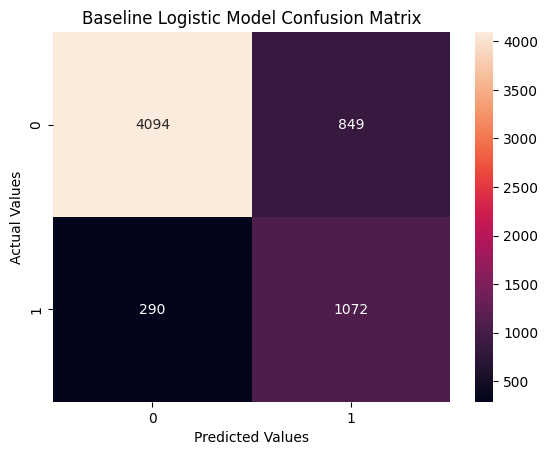

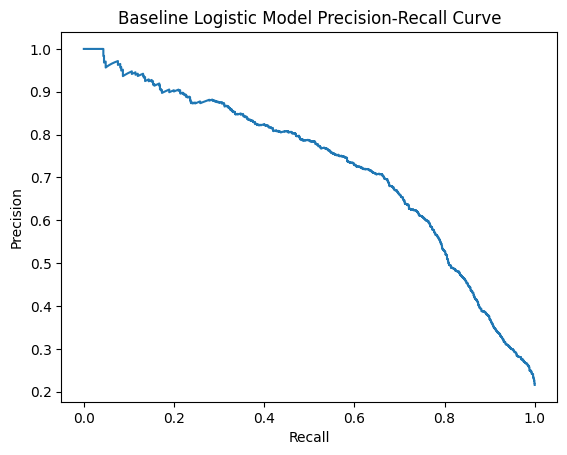

In [36]:
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

In [37]:
xg_model = Pipeline([
      ('preprocessor', preprocessor_xg),
      ('classifier',XGBClassifier(learning_rate=0.1, scale_pos_weight=scale_weights, random_state=42))

  ])

xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constan...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

XGBoost Metrices:
Best Threshold : None
Accuracy:0.92
Precision:0.82
Recall:0.79
F1:0.81

XGBoost:classification_report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



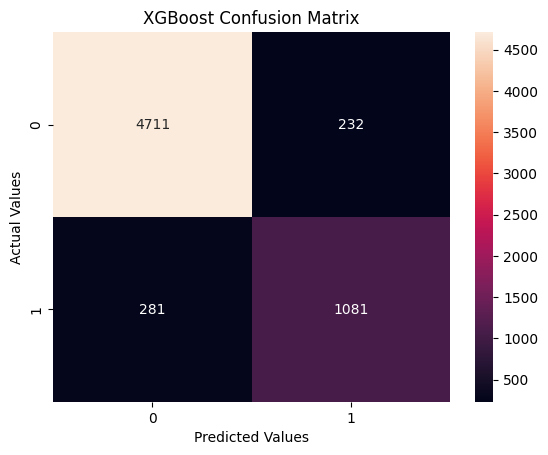

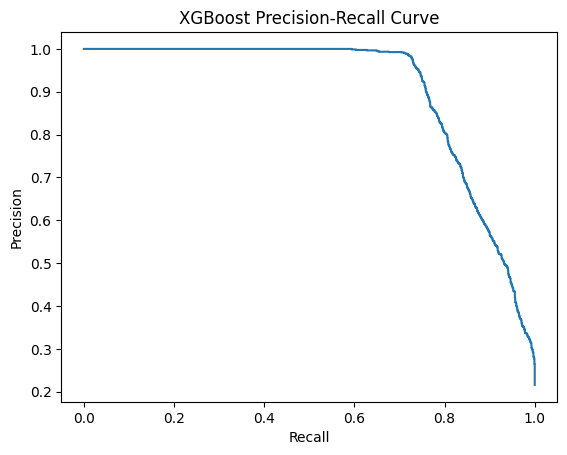

In [38]:
evaluate_model("XGBoost", xg_model, X_test, y_test)

In [39]:
from scipy.stats import uniform, randint

In [40]:
randint(0,4)

In [41]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3,9),
    "classifier__learning_rate":uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6, 0.4),
    "classifier__colsample_bytree":uniform(0.6, 0.4),
    "classifier__min_child_weight":randint(1, 10),
    "classifier__gamma":uniform(0, 5)
}
#lower gamma -> more splits -> complex tree -> higher overfitting risk
#higher gamma -> less splits -> simpler tree -> low overfitting risk

In [42]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter= 150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001F8FB6BCCE0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001F8FA31D190>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000001F8FA3C7C20>},
                   scoring='average_precision', verbose=1)

In [43]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [44]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.9126780785143194),
 'classifier__gamma': np.float64(0.8473516308205126),
 'classifier__learning_rate': np.float64(0.09566778110144634),
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 3,
 'classifier__n_estimators': 554,
 'classifier__subsample': np.float64(0.8845976587189017)}

Logistic Regression Metrices:
Best Threshold : None
Accuracy:0.82
Precision:0.56
Recall:0.79
F1:0.65

Logistic Regression:classification_report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



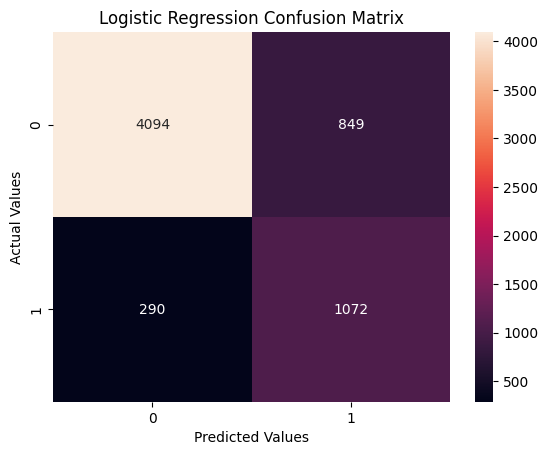

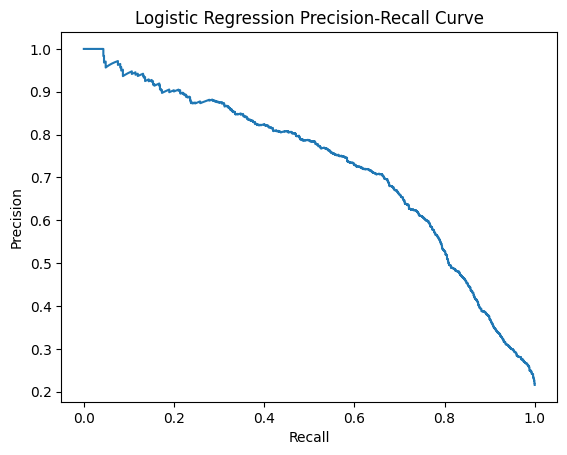

In [45]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

XGBoost Metrices:
Best Threshold : None
Accuracy:0.92
Precision:0.82
Recall:0.80
F1:0.81

XGBoost:classification_report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.80      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



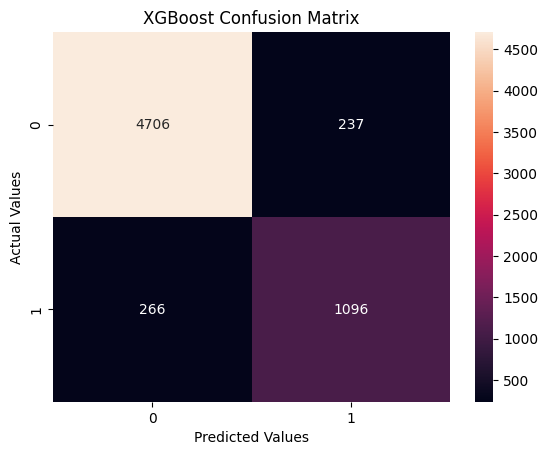

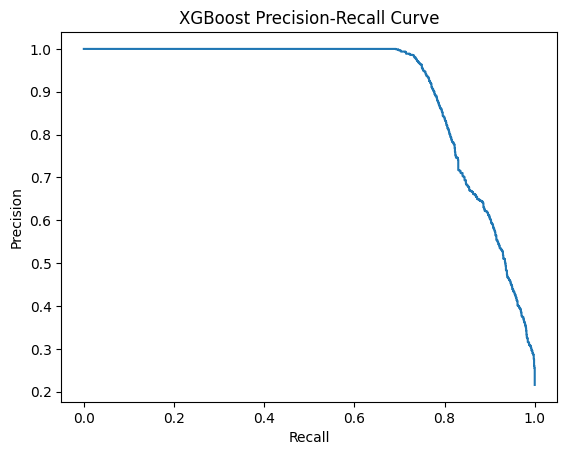

In [46]:
#Passing ther XGBoost model after performing Hyperparameter Tunning
evaluate_model("XGBoost", random_search, X_test, y_test)

In [47]:
# NOW WE, have to perform random forest, adaboost and xgboost


c:\Users\ramje\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ramje\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ramje\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, 

XGBoost Metrices:
Best Threshold : 0.9996131062507629
Accuracy:0.78
Precision:0.00
Recall:0.00
F1:0.00

XGBoost:classification_report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       0.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.61      0.78      0.69      6305



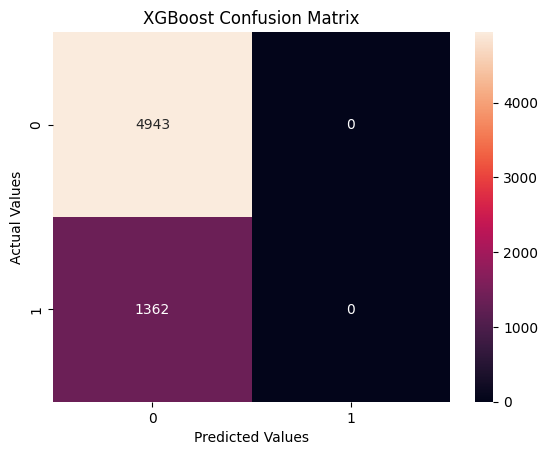

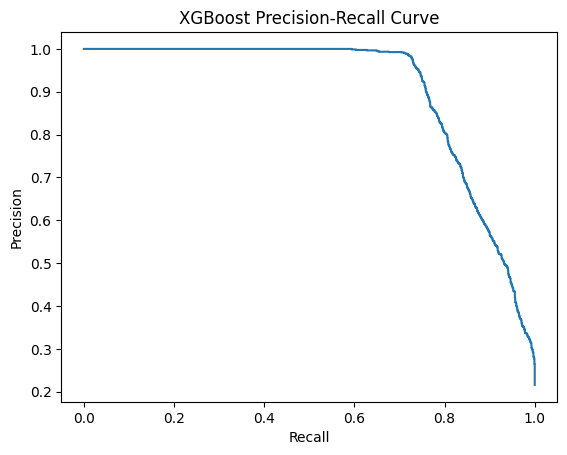

In [48]:
prob = xg_model.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

f1 = 2 * (precisions-recalls)/ ( precisions + recalls + 1e-9)

best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

evaluate_model("XGBoost", xg_model, X_test, y_test, best_threshold)






In [49]:
"""
Methods by which we can fix the poorly calibreated model.
1.Platt Scaling/ Sigmoid -> Adjust the probabilities using a sigmoid curve.
2.Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibration)
3.Temperature Scaling -> Adjust the confidence of neural-network predictions  predictions using one temperature
"""

'\nMethods by which we can fix the poorly calibreated model.\n1.Platt Scaling/ Sigmoid -> Adjust the probabilities using a sigmoid curve.\n2.Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibration)\n3.Temperature Scaling -> Adjust the confidence of neural-network predictions  predictions using one temperature\n'

In [50]:
#1. Calibreated XGBoost model

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)



CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('impute',
                                                                                                    SimpleImputer(...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.09566778110144634),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=5,
                                                                max_leaves=None,
                                                                min_child_weight=3,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=554,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [51]:
#2. Get probabilities
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]



In [52]:
uncalibrated

array([0.8254656 , 0.25111562, 0.9782833 , ..., 0.48520026, 0.07587515,
       0.05467961], shape=(6305,), dtype=float32)

In [53]:
calibrated

array([0.63151396, 0.03024437, 0.94807862, ..., 0.49140094, 0.02216812,
       0.01644728], shape=(6305,))

In [54]:
#3.Create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins = 10)


In [55]:
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins = 10)

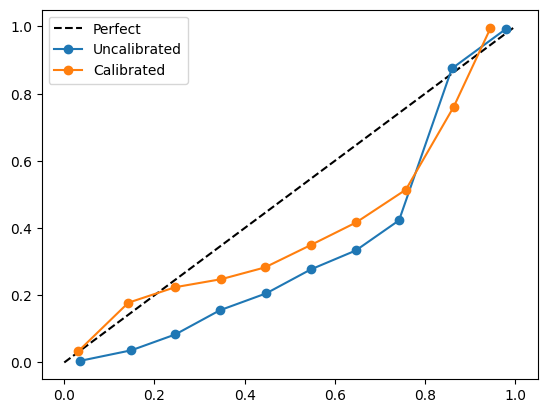

In [56]:
#4.Plot
plt.plot([0,1], [0,1], 'k--', label="Perfect")

plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label="Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label="Calibrated"
)

plt.legend()

In [57]:
#SHAP -> Shapley Additive Explanations
#Ans.-> Shap tells which features pushed the predictions p or down and how much?

#1. Installl SHAP if not exists
!pip install shap
import shap




[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ----------- 524.3/751.9 kB 17.5 MB/s eta 0:00:01
   --------------------------- ----------- 524.3/751.9 kB 17.5 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.3 MB/s  0:00:00

   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- -----

In [58]:
#2. Get the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']

In [59]:
#3. Transfrom X_test using the same preprocessing used for training.
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [60]:
#4. Get feature names after one-hot encoding, so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [61]:
feature_names

array(['num__person_age', 'num__person_income', 'num__person_emp_length',
       'num__loan_amnt', 'num__loan_int_rate', 'num__loan_percent_income',
       'num__cb_person_cred_hist_length',
       'cat__person_home_ownership_MORTGAGE',
       'cat__person_home_ownership_OTHER',
       'cat__person_home_ownership_OWN',
       'cat__person_home_ownership_RENT',
       'cat__loan_intent_DEBTCONSOLIDATION', 'cat__loan_intent_EDUCATION',
       'cat__loan_intent_HOMEIMPROVEMENT', 'cat__loan_intent_MEDICAL',
       'cat__loan_intent_PERSONAL', 'cat__loan_intent_VENTURE',
       'cat__loan_grade_A', 'cat__loan_grade_B', 'cat__loan_grade_C',
       'cat__loan_grade_D', 'cat__loan_grade_E', 'cat__loan_grade_F',
       'cat__loan_grade_G', 'cat__cb_person_default_on_file_N',
       'cat__cb_person_default_on_file_Y'], dtype=object)

In [62]:
#5. Convert to a Dataframe for cleaner SHAP Plots
import pandas as pd
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [63]:
#6. Create SHAP eplainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)


In [64]:
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)

In [65]:
shap_values[5]

array([ 2.5693566e-02, -8.3614630e-01, -1.7286925e-02, -8.7159630e-03,
       -5.8070445e-01, -4.1112086e-01,  5.0949983e-02,  6.0737142e-03,
       -6.1365054e-04,  8.3771028e-02, -3.0887976e-01, -4.9950812e-02,
       -3.1072120e-03, -4.4103891e-02, -8.1458546e-02, -2.0882446e-02,
        1.7620784e-01,  1.1165806e-01, -1.7614496e-01,  5.6751363e-02,
       -7.8791454e-02, -2.2548350e-02, -1.2131979e-02, -9.6205277e-03,
       -1.0001900e-02,  0.0000000e+00], dtype=float32)

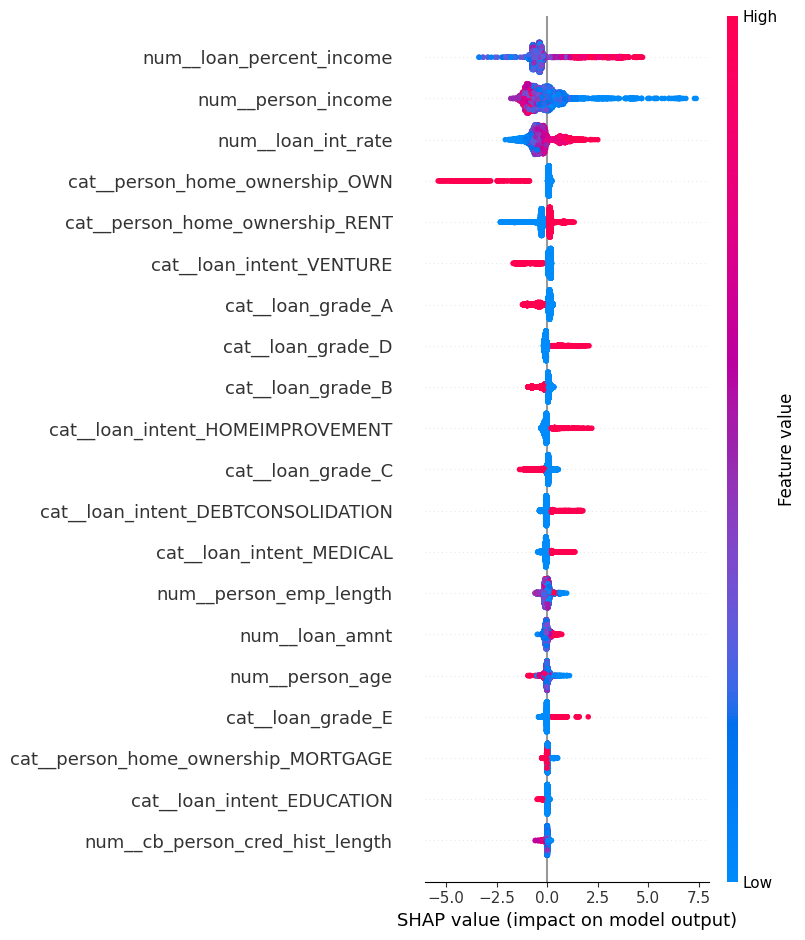

In [66]:
shap.summary_plot(shap_values, X_test_df)

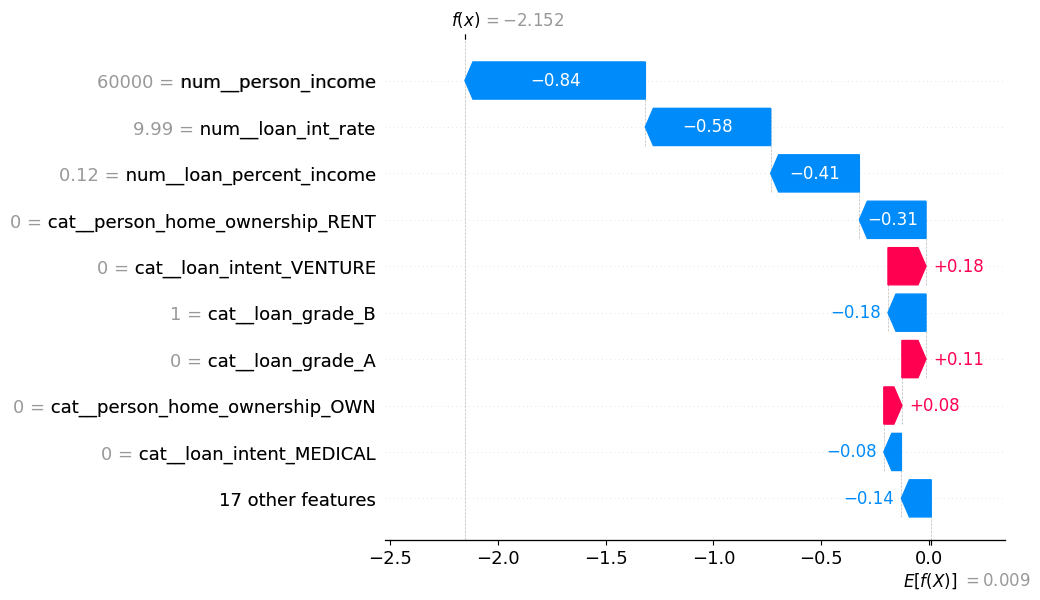

In [67]:
#1. Pick one row to explain, e.g. the 5th applicant in the test set.
row_index = 5

#2. draw a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

In [68]:
#Get Prediction from the best performing XGBoost mode on the test set
y_pred = random_search.predict(X_test)


In [69]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted']=y_pred



In [70]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [71]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual'] == 0) & ( result_df['predicted'] == 1)]

#Identify false Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]


In [72]:
print(f"False Positive : {len(false_positive)}")
print(f"false Negative : {len(false_negative)}")

False Positive : 237
false Negative : 266


In [73]:
#False Negative >  False Positive

In [74]:
#Save the Final Model

In [75]:
import joblib
joblib.dump(calibrated_model, "credit_risk_model.pkl")


['credit_risk_model.pkl']

In [76]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']

In [77]:
from sklearn.metrics import precision_recall_curve
import numpy as np

#1. Get probabilities from the CALIBRATED model, not the old xg_model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

#2. Re-run the same threshold search, now on the correct probability scale
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)
f1_scores = 2 * ( precisions * recalls) / ( precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold :", best_threshold)

New threshold : 0.6880779199323505


In [78]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']

In [79]:
%pip install --force-reinstall scikit-learn==1.6.1

  Using cached scikit_learn-1.6.1-cp312-cp312-win_amd64.whl.metadata (15 kB)
  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.6.1-cp312-cp312-win_amd64.whl (11.1 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl (12.6 MB)
Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl (36.7 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

  Attempting uninstall: threadpoolctl

    Found existing installation: threadpoolctl 3.8.0

    Uninstalling threadpoolctl-3.8.0:

   ---------------------------------------- 0/6 [threadpoolctl]
   ------------------------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.0 requires numpy<2.2,>=1.24, but you have numpy 2.5.4 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.5.4 which is incompatible.
ydata-profiling 4.18.4 requires scipy<1.17,>=1.8, but you have scipy 1.18.1 which is incompatible.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [80]:
import sklearn
import xgboost
import numpy
import scipy

print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)

print(type(xg_model))
print(type(best_model))
print(type(calibrated_model))

Scikit-learn: 1.6.1
XGBoost: 3.4.1
NumPy: 2.5.4
SciPy: 1.18.1
<class 'sklearn.pipeline.Pipeline'>
<class 'sklearn.pipeline.Pipeline'>
<class 'sklearn.calibration.CalibratedClassifierCV'>
